In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import pandas as pd

important_columns = [
    "chief_complaint_text",
    "age",
    "sex",
    "ems_arrival",
    "temp",
    "heart_rate",
    "resp_rate",
    "sys_bp",
    "dias_bp",
    "spo2",
    "pain_score",
    "seen_last_72h",
    "episode",
    "is_injury_poison",
    "hist_alzheimers",
    "hist_asthma",
    "hist_cancer",
    "hist_stroke",
    "hist_ckd",
    "hist_copd",
    "hist_chf",
    "hist_cad",
    "hist_depression",
    "hist_diabetes_t1",
    "hist_diabetes_t2",
    "hist_diabetes_unspec",
    "hist_esrd",
    "hist_pe",
    "hist_hiv",
    "hist_high_cholesterol",
    "hist_hypertension",
    "hist_obesity",
    "hist_sleep_apnea",
    "hist_osteoporosis",
    "hist_substance_abuse",

    "target_triage_acuity"
]

df = pd.read_csv(
    "./data/nhamcs_data_2018_22.csv",
    usecols=important_columns
)


In [5]:
df.columns

Index(['ems_arrival', 'age', 'sex', 'temp', 'heart_rate', 'resp_rate',
       'sys_bp', 'dias_bp', 'spo2', 'pain_score', 'seen_last_72h', 'episode',
       'is_injury_poison', 'hist_alzheimers', 'hist_asthma', 'hist_cancer',
       'hist_stroke', 'hist_ckd', 'hist_copd', 'hist_chf', 'hist_cad',
       'hist_depression', 'hist_diabetes_t1', 'hist_diabetes_t2',
       'hist_diabetes_unspec', 'hist_esrd', 'hist_pe', 'hist_hiv',
       'hist_high_cholesterol', 'hist_hypertension', 'hist_obesity',
       'hist_sleep_apnea', 'hist_osteoporosis', 'hist_substance_abuse',
       'target_triage_acuity', 'chief_complaint_text'],
      dtype='object')

In [6]:
df.head()

,ems_arrival,age,sex,temp,heart_rate,resp_rate,sys_bp,dias_bp,spo2,pain_score,...,hist_pe,hist_hiv,hist_high_cholesterol,hist_hypertension,hist_obesity,hist_sleep_apnea,hist_osteoporosis,hist_substance_abuse,target_triage_acuity,chief_complaint_text
0,No,5,Male,101.5,140.0,20.0,104.0,49.0,98.0,0.0,...,0,0,0,0,0,0,0,0,4,fever. throat soreness
1,No,5,Female,99.9,122.0,22.0,NaN,NaN,96.0,6.0,...,0,0,0,0,0,0,0,0,4,"injury, other and unspecified, of foo.... foot..."
2,No,0,Male,100.6,166.0,36.0,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,4,fever. cough
3,No,21,Female,97.0,77.0,18.0,128.0,68.0,100.0,10.0,...,0,0,0,0,0,0,0,0,4,"abdominal pain, cramps, spasms. chest pain. po..."
4,No,26,Female,97.1,91.0,18.0,133.0,78.0,99.0,10.0,...,0,0,0,0,0,0,0,0,4,"injury, other and unspecified, of foo..."


In [7]:
print(df["target_triage_acuity"].value_counts())

target_triage_acuity
3    29568
4    16715
2     8597
5     2398
1      846
Name: count, dtype: int64


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58124 entries, 0 to 58123
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ems_arrival            58124 non-null  object 
 1   age                    58124 non-null  int64  
 2   sex                    58124 non-null  object 
 3   temp                   56079 non-null  float64
 4   heart_rate             56475 non-null  float64
 5   resp_rate              56542 non-null  float64
 6   sys_bp                 52972 non-null  float64
 7   dias_bp                52925 non-null  float64
 8   spo2                   55922 non-null  float64
 9   pain_score             43319 non-null  float64
 10  seen_last_72h          55442 non-null  float64
 11  episode                58124 non-null  object 
 12  is_injury_poison       56267 non-null  object 
 13  hist_alzheimers        58124 non-null  int64  
 14  hist_asthma            58124 non-null  int64  
 15  hi

In [9]:
numeric_var = []
categoric_var = []
text_var = []

for col in df.columns:

    if col == "chief_complaint_text":
        text_var.append(col)

    elif df[col].dtype in ["object", "category"] or df[col].nunique() < 15:
        categoric_var.append(col)

    else:
        numeric_var.append(col)

In [10]:
numeric_var

['age', 'temp', 'heart_rate', 'resp_rate', 'sys_bp', 'dias_bp', 'spo2']

In [11]:
categoric_var

['ems_arrival',
 'sex',
 'pain_score',
 'seen_last_72h',
 'episode',
 'is_injury_poison',
 'hist_alzheimers',
 'hist_asthma',
 'hist_cancer',
 'hist_stroke',
 'hist_ckd',
 'hist_copd',
 'hist_chf',
 'hist_cad',
 'hist_depression',
 'hist_diabetes_t1',
 'hist_diabetes_t2',
 'hist_diabetes_unspec',
 'hist_esrd',
 'hist_pe',
 'hist_hiv',
 'hist_high_cholesterol',
 'hist_hypertension',
 'hist_obesity',
 'hist_sleep_apnea',
 'hist_osteoporosis',
 'hist_substance_abuse',
 'target_triage_acuity']

In [12]:
text_var

['chief_complaint_text']

In [13]:
x=df["temp"].mean()
df.fillna({"temp":x},inplace=True)#dictionary({key:value})

In [14]:
x=df["heart_rate"].mean()
df.fillna({"heart_rate":x},inplace=True)#dictionary({key:value})

In [15]:
x=df["resp_rate"].mean()
df.fillna({"resp_rate":x},inplace=True)#dictionary({key:value})

In [16]:
x=df["sys_bp"].mean()
df.fillna({"sys_bp":x},inplace=True)#dictionary({key:value})

In [17]:
x=df["dias_bp"].mean()
df.fillna({"dias_bp":x},inplace=True)#dictionary({key:value})

In [18]:
x=df["spo2"].mean()
df.fillna({"spo2":x},inplace=True)#dictionary({key:value})

In [19]:
x=df["pain_score"].mode()[0]
df.fillna({"pain_score":x},inplace=True)#dictionary({key:value})

In [20]:
x = df["is_injury_poison"].mode()[0]
df.fillna({"is_injury_poison": x}, inplace=True)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58124 entries, 0 to 58123
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ems_arrival            58124 non-null  object 
 1   age                    58124 non-null  int64  
 2   sex                    58124 non-null  object 
 3   temp                   58124 non-null  float64
 4   heart_rate             58124 non-null  float64
 5   resp_rate              58124 non-null  float64
 6   sys_bp                 58124 non-null  float64
 7   dias_bp                58124 non-null  float64
 8   spo2                   58124 non-null  float64
 9   pain_score             58124 non-null  float64
 10  seen_last_72h          55442 non-null  float64
 11  episode                58124 non-null  object 
 12  is_injury_poison       58124 non-null  object 
 13  hist_alzheimers        58124 non-null  int64  
 14  hist_asthma            58124 non-null  int64  
 15  hi

In [22]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 17


In [23]:
duplicate_rows = df[df.duplicated(keep=False)]

print(duplicate_rows)

      ems_arrival  age     sex        temp  heart_rate  resp_rate      sys_bp  \
209            No    6  Female   98.500000  100.000000  20.000000  135.000000   
210            No    6  Female   98.500000  100.000000  20.000000  135.000000   
3037           No   16  Female   98.400000   83.000000  16.000000  107.000000   
3115           No   16  Female   98.400000   83.000000  16.000000  107.000000   
6374           No    0    Male   98.306437   92.966197  19.465636  134.898286   
10543          No    8  Female   99.900000  120.000000  24.000000  113.000000   
10544          No    8  Female   99.900000  120.000000  24.000000  113.000000   
10563          No    7  Female  101.600000  134.000000  20.000000  112.000000   
10564          No    7  Female  101.600000  134.000000  20.000000  112.000000   
12205          No    2    Male  100.200000  159.000000  30.000000  134.898286   
12207          No    2    Male  100.200000  159.000000  30.000000  134.898286   
17245          No   38  Fema

In [24]:
df = df.drop_duplicates()

In [25]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


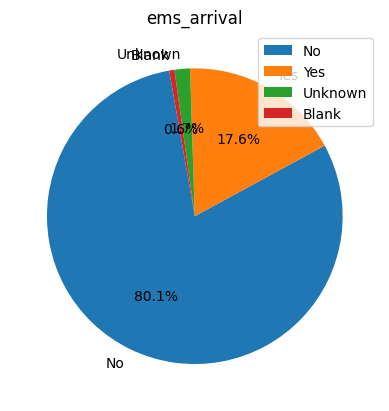

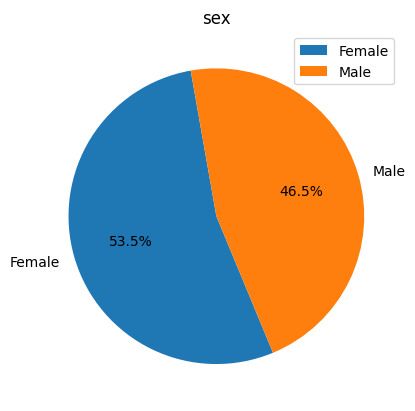

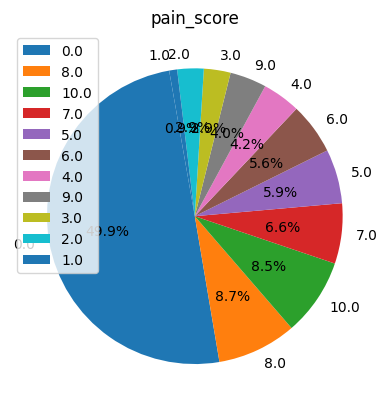

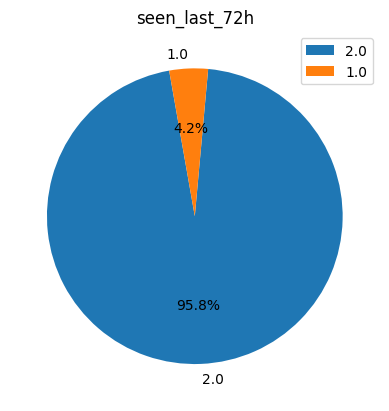

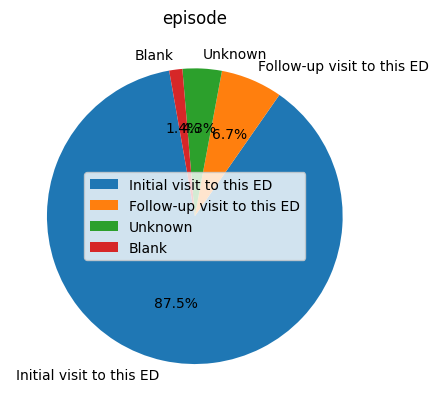

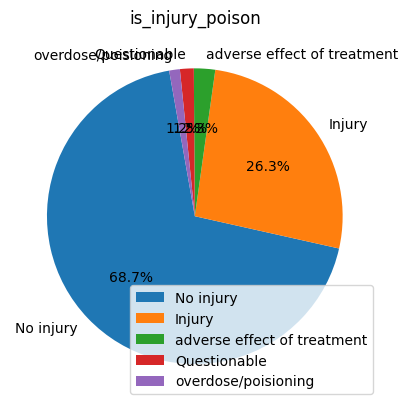

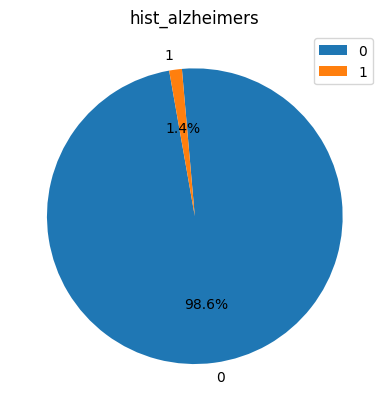

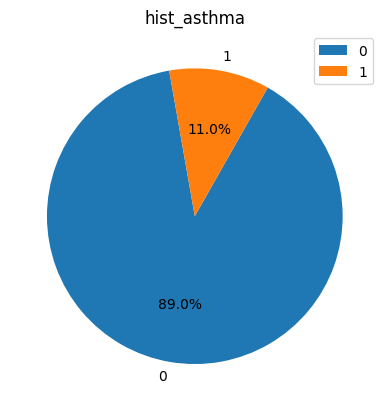

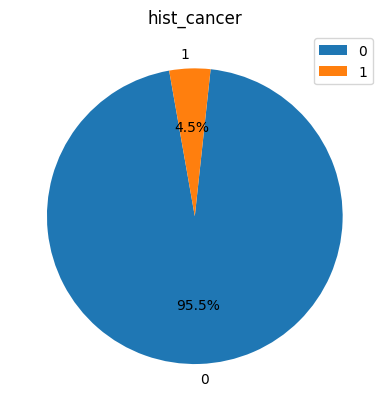

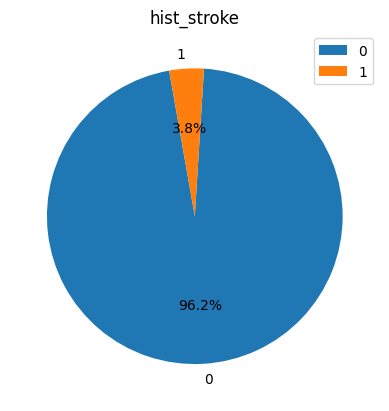

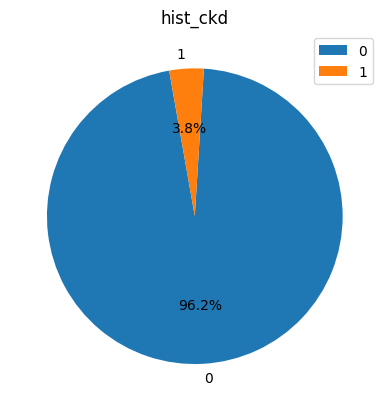

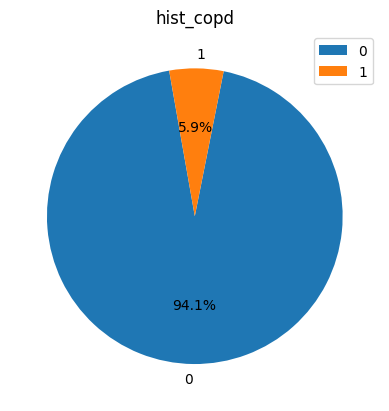

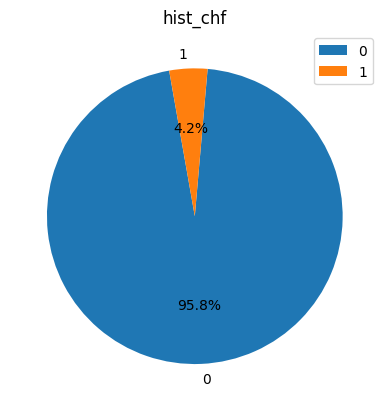

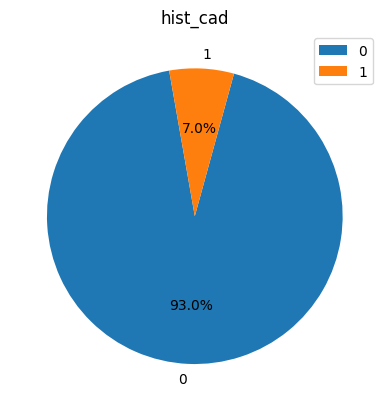

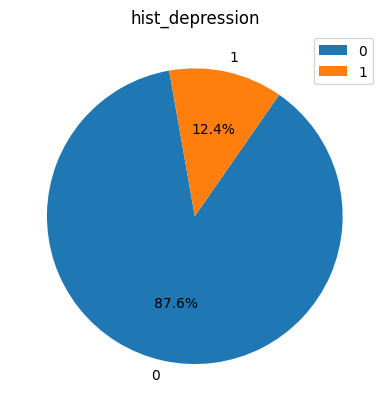

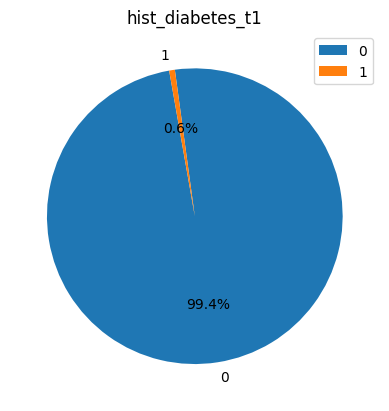

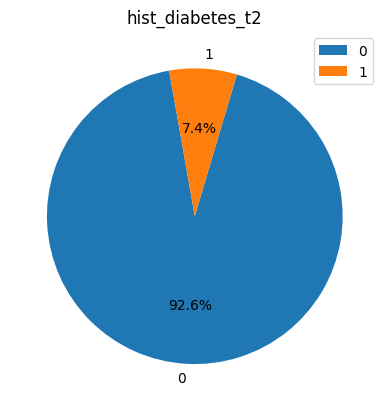

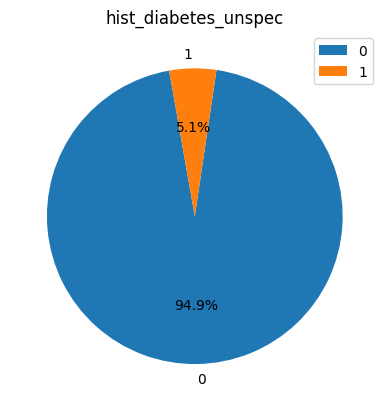

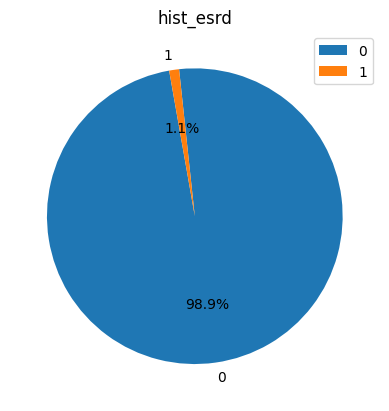

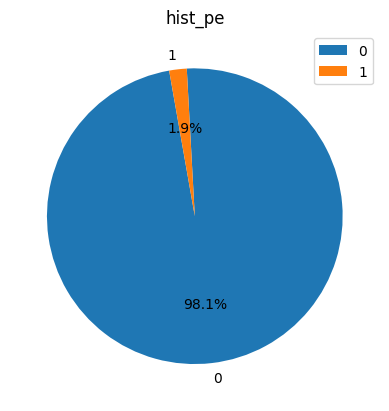

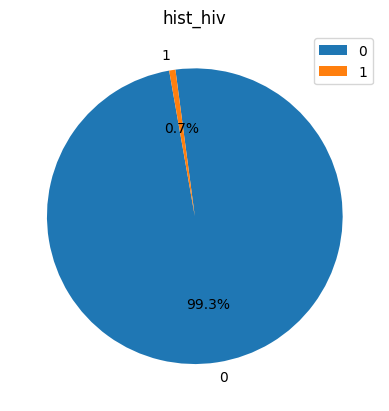

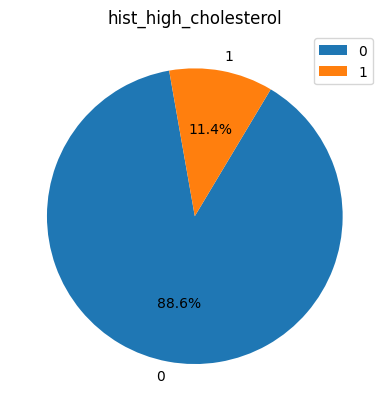

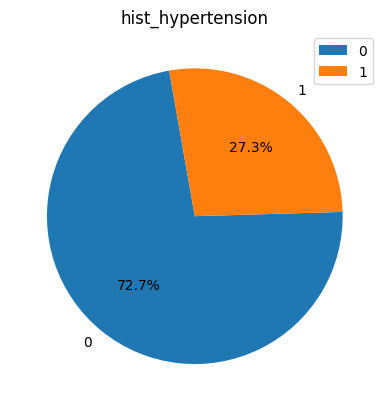

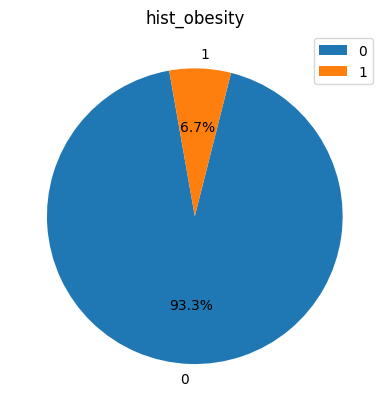

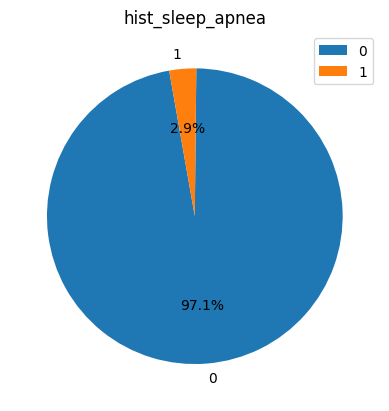

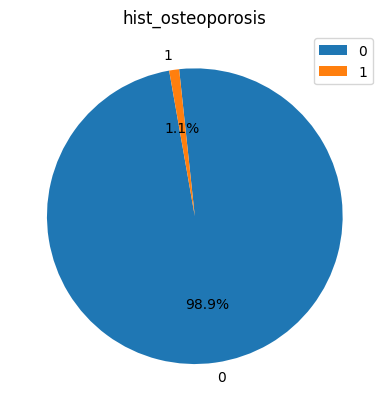

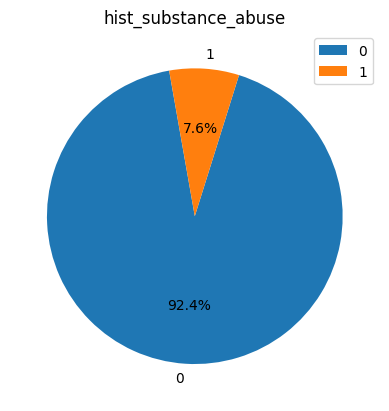

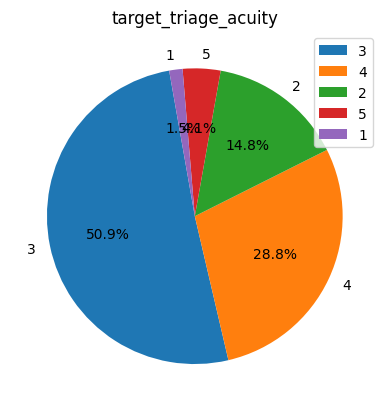

In [26]:
for i in categoric_var:
    observation_values=list(df[i].value_counts().index)
    total_observation_values=list(df[i].value_counts())
    plt.pie(total_observation_values,
    labels=observation_values,
    autopct='%1.1f%%',
    startangle=100,
    labeldistance=1.1)
    plt.title(i)
    plt.legend()
    plt.show()



In [27]:
df["ems_arrival"] = df["ems_arrival"].replace("Blank", "No")
df["ems_arrival"] = df["ems_arrival"].replace("Unknown", "No")

In [28]:
df["seen_last_72h"] = df["seen_last_72h"].replace(2,0)

In [29]:
df["episode"] = df["episode"].replace("Blank", "Initial visit to this ED")
df["episode"] = df["episode"].replace("Unknown", "Initial visit to this ED")

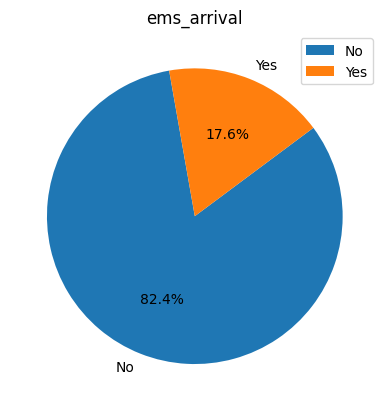

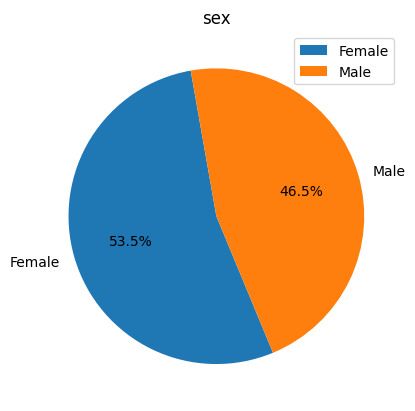

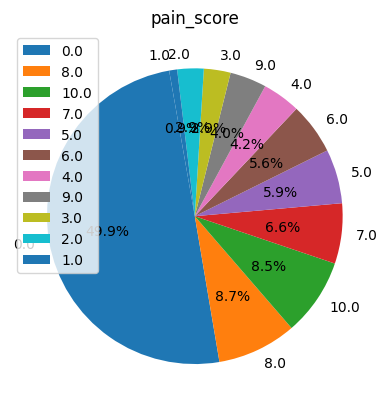

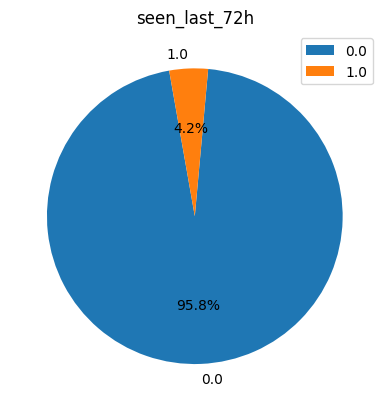

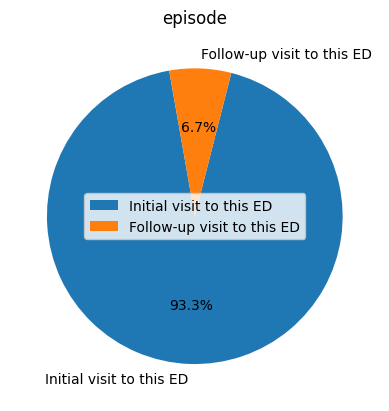

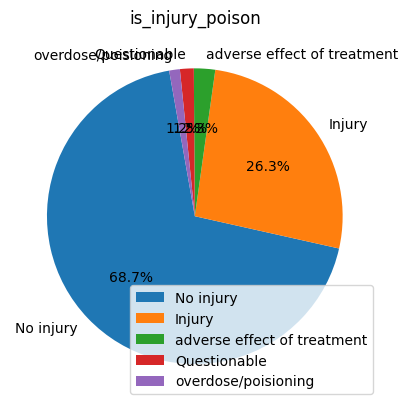

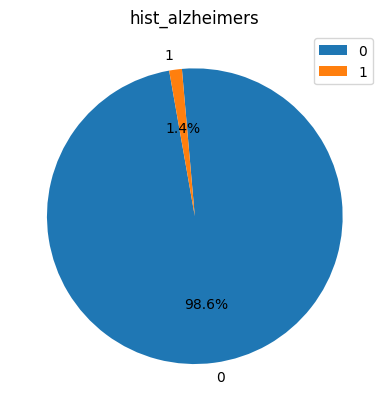

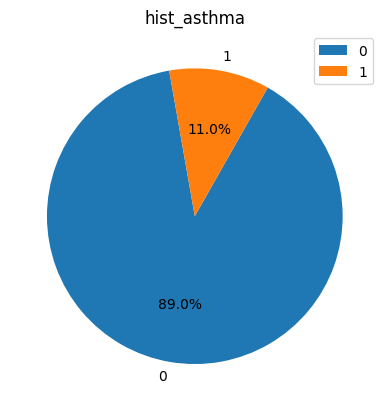

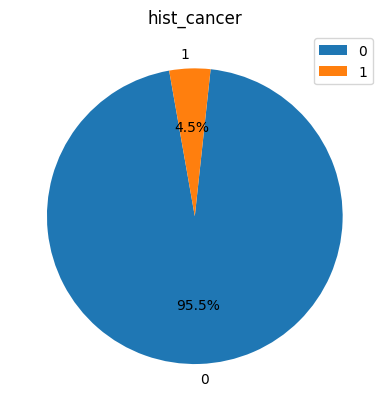

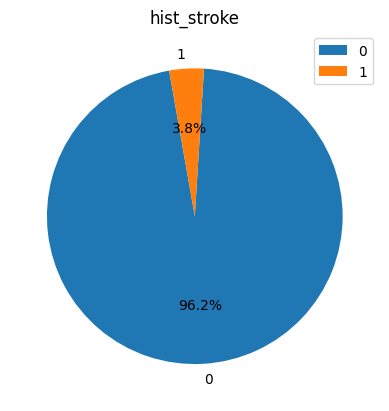

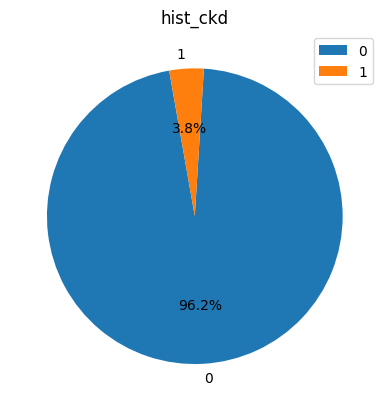

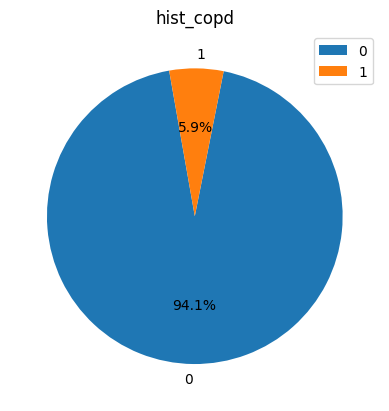

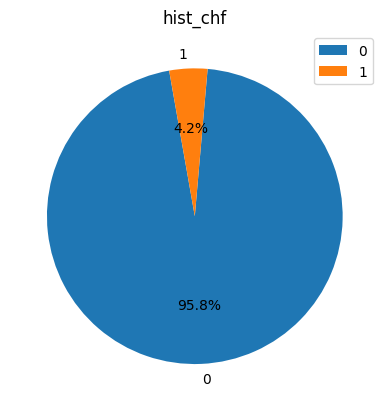

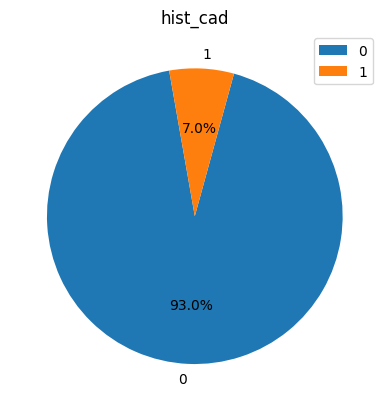

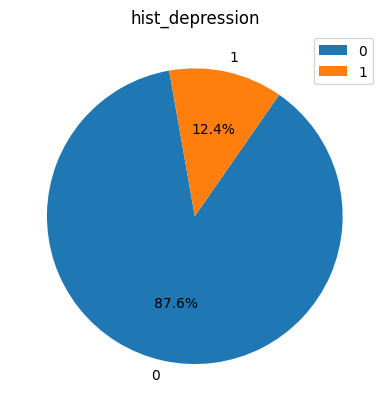

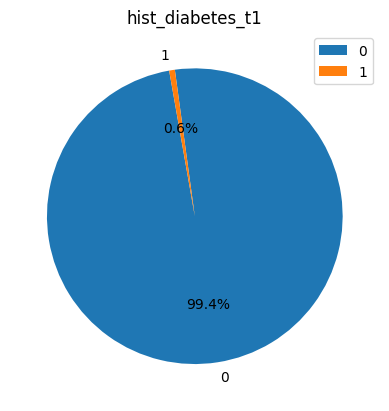

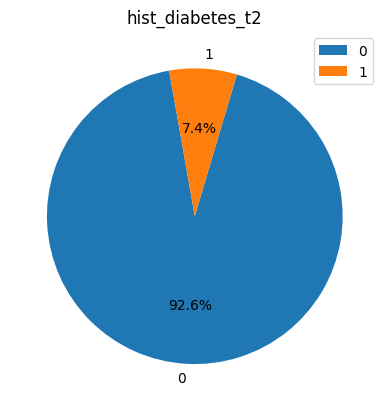

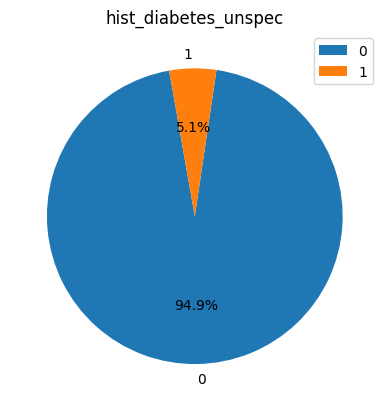

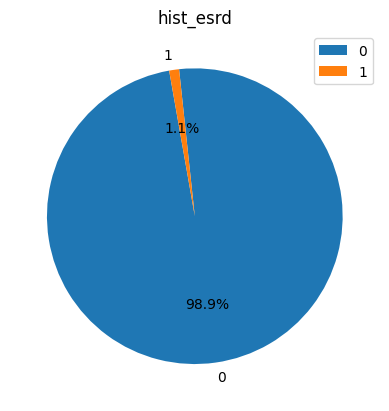

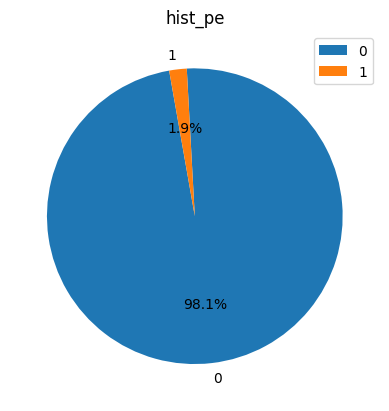

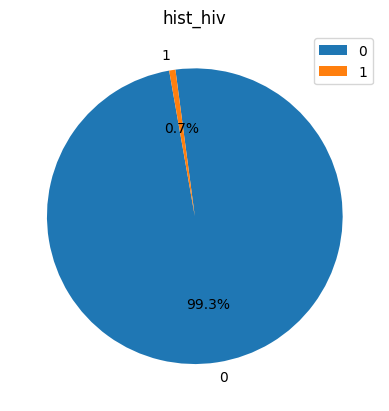

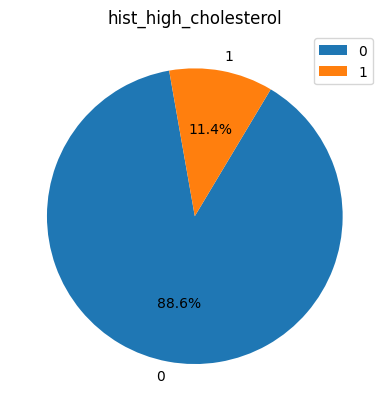

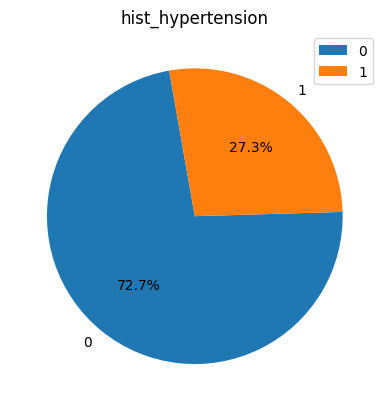

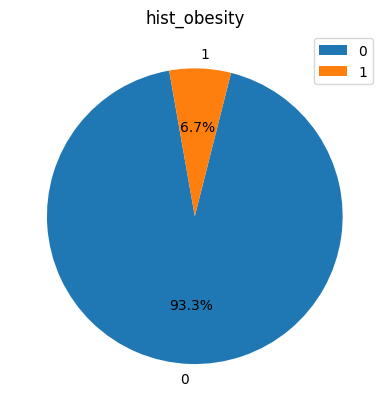

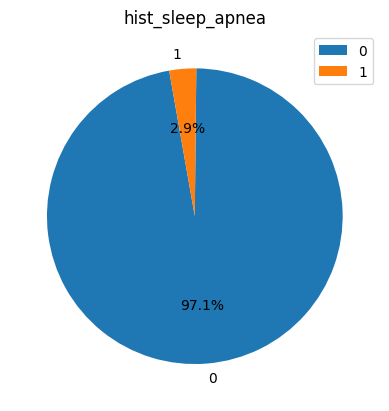

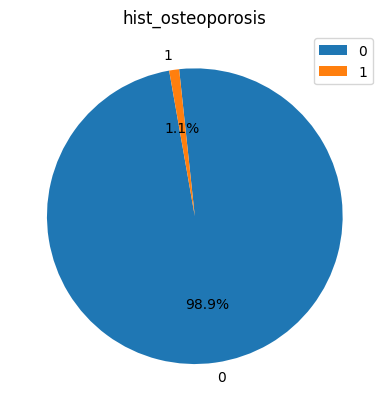

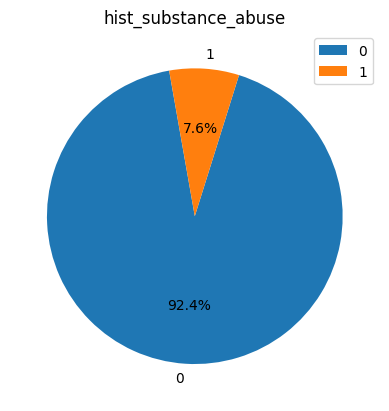

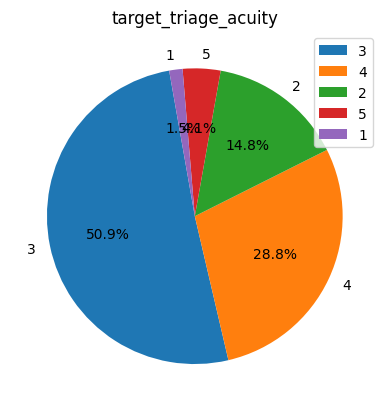

In [30]:
for i in categoric_var:
    observation_values=list(df[i].value_counts().index)
    total_observation_values=list(df[i].value_counts())
    plt.pie(total_observation_values,
    labels=observation_values,
    autopct='%1.1f%%',
    startangle=100,
    labeldistance=1.1)
    plt.title(i)
    plt.legend()
    plt.show()


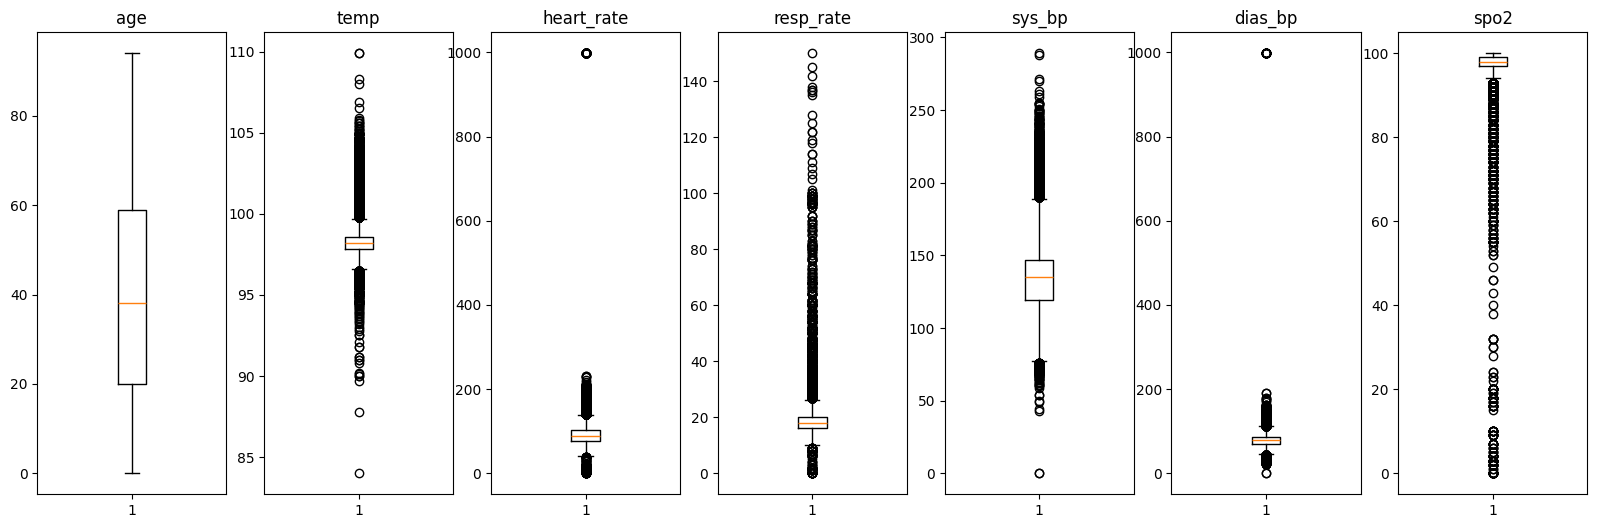

In [31]:
fig ,(ax1,ax2,ax3,ax4,ax5,ax6,ax7)=plt.subplots(1,7,figsize=(20,6))
ax1.boxplot(df["age"])
ax1.set_title("age")

ax2.boxplot(df["temp"])
ax2.set_title("temp")

ax3.boxplot(df["heart_rate"])
ax3.set_title("heart_rate")

ax4.boxplot(df["resp_rate"])
ax4.set_title("resp_rate")

ax5.boxplot(df["sys_bp"])
ax5.set_title("sys_bp")

ax6.boxplot(df["dias_bp"])
ax6.set_title("dias_bp")

ax7.boxplot(df["spo2"])
ax7.set_title("spo2")
plt.show()

In [32]:
df[["age","temp","heart_rate","resp_rate","sys_bp","dias_bp","spo2"]].agg(["skew"]).transpose()

,skew
age,0.187264
temp,1.857822
heart_rate,15.641135
resp_rate,6.633568
sys_bp,0.757649
dias_bp,24.813611
spo2,-12.465214


In [33]:
from scipy import stats
from scipy.stats import zscore
from scipy.stats.mstats import winsorize
def iqr(df, var):
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)

    iqr_value = q3 - q1

    lower_bound = q1 - 1.5 * iqr_value
    upper_bound = q3 + 1.5 * iqr_value

    print(f"{var} lower bound: {lower_bound}")
    print(f"{var} upper bound: {upper_bound}")

    df[var] = df[var].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [34]:
print("Min temp:", df["temp"].min())
print("Max temp:", df["temp"].max())

Min temp: 84.0
Max temp: 109.9


In [35]:
print("Min heart_rate:", df["heart_rate"].min())
print("Max heart_rate:", df["heart_rate"].max())

Min heart_rate: 0.0
Max heart_rate: 998.0


In [36]:
df["heart_rate"].nsmallest(55)

,heart_rate
461,0.0
2929,0.0
3008,0.0
3092,0.0
3094,0.0
3095,0.0
3098,0.0
3107,0.0
16791,0.0
30756,0.0


In [37]:
df["heart_rate"].nlargest(75)

,heart_rate
16884,998.0
24756,998.0
24826,998.0
33454,998.0
34361,998.0
...,...
14107,232.0
46853,232.0
32140,229.0
10769,228.0


In [38]:
print((df["heart_rate"] == 0).sum())
print((df["heart_rate"] == 998).sum())

15
70


In [39]:
df.loc[
    df["heart_rate"] > 240,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("heart_rate")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity
16884,46,Male,998.0,98.6,18.0,148.0,89.0,100.0,3.0,3
24756,30,Female,998.0,98.4,18.0,106.0,88.0,97.0,0.0,4
24826,91,Male,998.0,97.9,16.0,147.0,58.0,100.0,0.0,3
33454,61,Female,998.0,97.6,16.0,144.0,86.0,100.0,10.0,3
34361,24,Male,998.0,98.7,45.0,120.0,80.0,90.0,4.0,3
...,...,...,...,...,...,...,...,...,...,...
54489,59,Male,998.0,97.9,40.0,110.0,90.0,90.0,9.0,3
54490,21,Male,998.0,97.9,50.0,130.0,90.0,80.0,0.0,3
54491,50,Female,998.0,98.9,40.0,120.0,90.0,100.0,7.0,3
54492,51,Female,998.0,97.9,30.0,130.0,90.0,80.0,6.0,3


In [40]:
import numpy as np

df.loc[
    (df["heart_rate"] < 30) | (df["heart_rate"] == 998),
    "heart_rate"
] = np.nan


df["heart_rate"] = df["heart_rate"].fillna(df["heart_rate"].median())

In [41]:
df.loc[
    df["heart_rate"] < 30,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("heart_rate")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity


In [42]:
print("Min resp_rate:", df["resp_rate"].min())
print("Max resp_rate:", df["resp_rate"].max())

Min resp_rate: 0.0
Max resp_rate: 150.0


In [43]:
df.loc[
    df["resp_rate"] >100,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("resp_rate")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity
23904,22,Female,107.000000,99.400000,101.0,121.000000,81.000000,98.000000,0.0,4
30145,25,Male,97.000000,98.000000,105.0,137.000000,82.000000,100.000000,8.0,4
54145,29,Female,116.000000,98.500000,107.0,107.000000,86.000000,99.000000,10.0,2
28364,7,Female,143.000000,99.100000,109.0,109.000000,76.000000,98.000000,8.0,4
7294,41,Female,111.000000,100.500000,111.0,148.000000,96.000000,97.000000,7.0,3
36108,49,Female,82.000000,96.800000,114.0,134.898286,151.000000,98.000000,0.0,3
54973,92,Female,92.966197,98.306437,114.0,134.898286,79.512518,97.417886,0.0,1
17689,85,Female,76.000000,97.800000,118.0,197.000000,86.000000,96.000000,0.0,3
14162,94,Female,92.966197,98.306437,119.0,146.000000,94.000000,90.000000,0.0,2
50873,87,Female,71.000000,97.700000,122.0,179.000000,67.000000,97.000000,9.0,2


In [44]:
median_resp = df.loc[
    (df["resp_rate"] >= 8) & (df["resp_rate"] <= 70),
    "resp_rate"
].median()

df.loc[
    (df["resp_rate"] < 8) | (df["resp_rate"] > 70),
    "resp_rate"
] = median_resp

In [45]:
print("Min resp_rate:", df["resp_rate"].min())
print("Max resp_rate:", df["resp_rate"].max())

Min resp_rate: 8.0
Max resp_rate: 70.0


In [46]:
print("Min dias_bp:", df["dias_bp"].min())
print("Max dias_bp:", df["dias_bp"].max())

Min dias_bp: 0.0
Max dias_bp: 998.0


In [47]:
df.loc[
    df["dias_bp"] >160,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("dias_bp")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity
14129,3,Female,153.0,97.800000,22.0,189.000000,161.0,96.000000,8.0,2
21839,59,Female,111.0,98.000000,20.0,201.000000,162.0,96.000000,5.0,2
38631,55,Female,104.0,100.700000,26.0,162.000000,162.0,94.000000,7.0,1
40790,75,Female,108.0,98.600000,20.0,201.000000,163.0,98.000000,8.0,3
31623,91,Male,52.0,97.500000,21.0,201.000000,163.0,100.000000,0.0,2
56044,38,Female,117.0,98.100000,18.0,289.000000,170.0,98.000000,10.0,2
55052,36,Female,126.0,99.000000,16.0,246.000000,175.0,98.000000,10.0,2
7390,60,Female,100.0,96.800000,19.0,254.000000,175.0,100.000000,7.0,2
39743,26,Female,107.0,97.100000,18.0,182.000000,176.0,97.000000,0.0,3
3196,75,Female,75.0,98.200000,18.0,178.000000,178.0,77.000000,4.0,3


In [48]:
median_dias = df.loc[~df["dias_bp"].isin([0, 998]), "dias_bp"].median()

df.loc[df["dias_bp"].isin([0, 998]), "dias_bp"] = median_dias

In [49]:
df.loc[
    df["dias_bp"] >260,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("dias_bp")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity


In [50]:
print("Min sys_bp:", df["sys_bp"].min())
print("Max sys_bp:", df["sys_bp"].max())

Min sys_bp: 0.0
Max sys_bp: 289.0


In [51]:
df.loc[
    df["sys_bp"] <10,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("sys_bp")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity
31748,94,Male,89.0,98.306437,18.0,0.0,79.512518,0.0,0.0,1
36606,64,Female,89.0,98.306437,18.0,0.0,79.512518,0.0,0.0,1


In [52]:
median_sys = df["sys_bp"].median()

df.loc[df["sys_bp"] == 0, "sys_bp"] = median_sys

In [53]:
print("Min spo2:", df["spo2"].min())
print("Max spo2:", df["spo2"].max())

Min spo2: 0.0
Max spo2: 100.0


In [54]:
df.loc[
    df["spo2"] <30,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("spo2")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity
461,32,Male,89.0,98.306437,18.0,134.898286,79.512518,0.0,0.0,5
2929,51,Male,89.0,98.306437,18.0,134.898286,79.512518,0.0,10.0,4
3107,16,Female,89.0,98.306437,18.0,134.898286,79.512518,0.0,0.0,3
3098,9,Female,89.0,98.306437,18.0,134.898286,79.512518,0.0,0.0,3
3095,16,Male,89.0,98.306437,18.0,134.898286,79.512518,0.0,0.0,2
...,...,...,...,...,...,...,...,...,...,...
54705,14,Female,75.0,97.600000,20.0,77.000000,50.000000,23.0,7.0,2
35277,39,Male,91.0,98.600000,22.0,163.000000,91.000000,23.0,10.0,1
19425,6,Female,110.0,100.200000,24.0,134.898286,79.512518,24.0,0.0,4
15045,3,Female,100.0,98.000000,24.0,134.898286,79.512518,24.0,0.0,4


In [55]:
median_spo2 = df.loc[df["spo2"] >= 30, "spo2"].median()

df.loc[df["spo2"] < 30, "spo2"] = median_spo2

In [56]:
df.loc[
    df["spo2"] <30,
    [
        "age",
        "sex",
        "heart_rate",
        "temp",
        "resp_rate",
        "sys_bp",
        "dias_bp",
        "spo2",
        "pain_score",
        "target_triage_acuity"
    ]
].sort_values("spo2")

,age,sex,heart_rate,temp,resp_rate,sys_bp,dias_bp,spo2,pain_score,target_triage_acuity


In [57]:
import pandas as pd


categorical_cols = [
    col for col in categoric_var
    if col != "target_triage_acuity"
]


df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

pd.set_option("display.max_columns", None)

df.head()

,age,temp,heart_rate,resp_rate,sys_bp,dias_bp,spo2,target_triage_acuity,chief_complaint_text,ems_arrival_Yes,sex_Male,pain_score_1.0,pain_score_2.0,pain_score_3.0,pain_score_4.0,pain_score_5.0,pain_score_6.0,pain_score_7.0,pain_score_8.0,pain_score_9.0,pain_score_10.0,seen_last_72h_1.0,episode_Initial visit to this ED,is_injury_poison_No injury,is_injury_poison_Questionable,is_injury_poison_adverse effect of treatment,is_injury_poison_overdose/poisioning,hist_alzheimers_1,hist_asthma_1,hist_cancer_1,hist_stroke_1,hist_ckd_1,hist_copd_1,hist_chf_1,hist_cad_1,hist_depression_1,hist_diabetes_t1_1,hist_diabetes_t2_1,hist_diabetes_unspec_1,hist_esrd_1,hist_pe_1,hist_hiv_1,hist_high_cholesterol_1,hist_hypertension_1,hist_obesity_1,hist_sleep_apnea_1,hist_osteoporosis_1,hist_substance_abuse_1
0,5,101.5,140.0,20.0,104.000000,49.000000,98.000000,4,fever. throat soreness,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,5,99.9,122.0,22.0,134.898286,79.512518,96.000000,4,"injury, other and unspecified, of foo.... foot...",0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,100.6,166.0,36.0,134.898286,79.512518,97.417886,4,fever. cough,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,21,97.0,77.0,18.0,128.000000,68.000000,100.000000,4,"abdominal pain, cramps, spasms. chest pain. po...",0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,26,97.1,91.0,18.0,133.000000,78.000000,99.000000,4,"injury, other and unspecified, of foo...",0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [58]:
df[["age", "temp", "heart_rate", "resp_rate","sys_bp", "dias_bp", "spo2"]].agg(["skew"]).transpose()

,skew
age,0.187264
temp,1.857822
heart_rate,1.182466
resp_rate,3.700618
sys_bp,0.765064
dias_bp,0.446933
spo2,-6.370927


In [59]:
df["temp_log"] = np.log(df["temp"])
df["temp_sqrt"] = np.sqrt(df["temp"])

df[["temp", "temp_log", "temp_sqrt"]].agg(["skew"]).transpose()

,skew
temp,1.857822
temp_log,1.713009
temp_sqrt,1.786095


In [60]:
df.drop(columns=["temp", "temp_sqrt"], inplace=True)

In [61]:
df["heart_rate_sqrt"] = np.sqrt(df["heart_rate"])
df["heart_rate_log"] = np.log(df["heart_rate"])

df[
    ["heart_rate", "heart_rate_sqrt", "heart_rate_log"]
].agg(["skew"]).transpose()

,skew
heart_rate,1.182466
heart_rate_sqrt,0.731812
heart_rate_log,0.311780


In [62]:
df.drop(columns=["heart_rate", "heart_rate_sqrt"], inplace=True)

In [63]:
df["resp_rate_sqrt"] = np.sqrt(df["resp_rate"])
df["resp_rate_log"] = np.log(df["resp_rate"])

df[
    ["resp_rate", "resp_rate_sqrt", "resp_rate_log"]
].agg(["skew"]).transpose()

,skew
resp_rate,3.700618
resp_rate_sqrt,2.717489
resp_rate_log,1.920674


In [64]:
df.drop(columns=["resp_rate", "resp_rate_sqrt"], inplace=True)

In [65]:
df["sys_bp_sqrt"] = np.sqrt(df["sys_bp"])
df["sys_bp_log"] = np.log(df["sys_bp"])

df[
    ["sys_bp", "sys_bp_sqrt", "sys_bp_log"]
].agg(["skew"]).transpose()

,skew
sys_bp,0.765064
sys_bp_sqrt,0.421697
sys_bp_log,0.078380


In [66]:
df.drop(columns=["sys_bp", "sys_bp_sqrt"], inplace=True)

In [67]:
df["spo2_ref_log"] = np.log(101- df["spo2"])
df["spo2_ref_sqrt"] = np.sqrt(101- df["spo2"])

df[
    ["spo2", "spo2_ref_log", "spo2_ref_sqrt"]
].agg(["skew"]).transpose()

,skew
spo2,-6.370927
spo2_ref_log,0.139072
spo2_ref_sqrt,1.793134


In [68]:
df.drop(columns=["spo2", "spo2_ref_sqrt"], inplace=True)

In [69]:
from sklearn.preprocessing import RobustScaler

num_cols = [
    "age",
    "dias_bp",
    "temp_log",
    "heart_rate_log",
    "resp_rate_log",
    "sys_bp_log",
    "spo2_ref_log"
]

scaler = RobustScaler()

df[num_cols] = scaler.fit_transform(df[num_cols])

In [70]:
import re
def preprocess_text(text):


    if pd.isna(text):
        return ""


    text = str(text).lower()


    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bcannot\b", "can not", text)
    text = re.sub(r"\bdoesn't\b", "does not", text)
    text = re.sub(r"\bdidn't\b", "did not", text)
    text = re.sub(r"\bisn't\b", "is not", text)
    text = re.sub(r"\bwasn't\b", "was not", text)
    text = re.sub(r"\bweren't\b", "were not", text)
    text = re.sub(r"\bhasn't\b", "has not", text)
    text = re.sub(r"\bhaven't\b", "have not", text)


    text = re.sub(r"http\S+|www\.\S+", " ", text)

    text = re.sub(r"<.*?>", " ", text)

    text = re.sub(r"[^a-z0-9\s/\-+.%]", " ", text)


    text = re.sub(r"\s+", " ", text)


    text = text.strip()

    return text



df["chief_complaint_clean"] = (
    df["chief_complaint_text"]
    .apply(preprocess_text)
)


df[
    ["chief_complaint_text", "chief_complaint_clean"]
].head(20)

,chief_complaint_text,chief_complaint_clean
0,fever. throat soreness,fever. throat soreness
1,"injury, other and unspecified, of foo.... foot...",injury other and unspecified of foo.... foot a...
2,fever. cough,fever. cough
3,"abdominal pain, cramps, spasms. chest pain. po...",abdominal pain cramps spasms. chest pain. post...
4,"injury, other and unspecified, of foo...",injury other and unspecified of foo...
5,fever,fever
6,cough. nasal congestion,cough. nasal congestion
7,cough,cough
8,"injury, other and unspecified of head...",injury other and unspecified of head...
9,skin rash,skin rash


In [71]:
(df["chief_complaint_clean"] == "").sum()

np.int64(0)

In [72]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=12000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_text = tfidf.fit_transform(
    df["chief_complaint_clean"]
)

print("TF-IDF shape:", X_text.shape)

TF-IDF shape: (58107, 9888)
